# **Lab 9 - Morphological Operations (Solution)**

**Student ID:** 2240002024

**Objective:** Apply morphological operations (erosion, dilation, opening and closing) to a new binary image, and investigate how the shape and size of the structuring element affect the result.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# New binary image (not the Erosion.jpg / Open_Closing.jpg used in the lab)
imgFile = 'images/Balls.png'

img = cv2.imread(imgFile, 0)

# Otsu threshold. The balls are black on a white background, so THRESH_BINARY_INV
# is used to make the balls white (foreground), because morphology works on white objects.
_, binary = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print('Image size:', img.shape)

Image size: (1234, 1274)


## **Task 1: Apply Morphological Operations to a New Image**

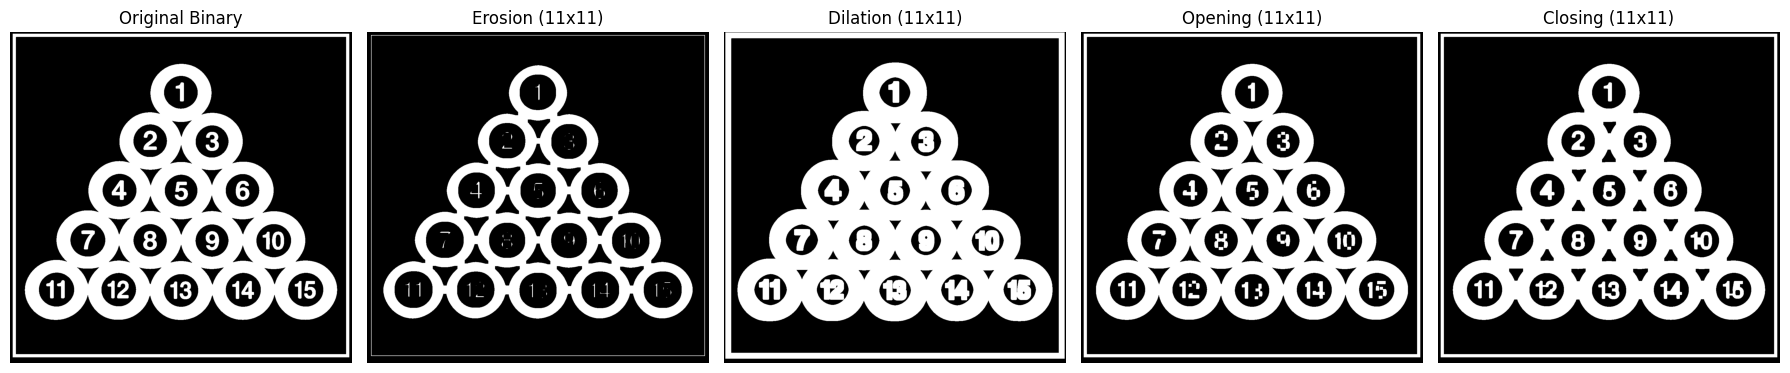

In [2]:
# 11x11 square kernel (all ones)
kernel = np.ones((11, 11), np.uint8)

eroded  = cv2.erode(binary, kernel, iterations=1)
dilated = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)   # erosion then dilation
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)  # dilation then erosion

titles = ['Original Binary', 'Erosion', 'Dilation', 'Opening', 'Closing']
images = [binary, eroded, dilated, opening, closing]

plt.figure(figsize=(18, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i] + ' (11x11)' if i else titles[i])
    plt.axis('off')
plt.tight_layout()
plt.savefig('results/task1_result.png', dpi=110, bbox_inches='tight')
plt.show()

### Explanation (Task 1)

- **Erosion:** white objects shrink. The rings become thinner, the digits become thin and broken, the frame line (12 px) almost disappears, and the black gaps between the balls get bigger.
- **Dilation:** white objects grow. The rings, digits and frame become thicker, and the black gaps between the balls shrink to small triangles.
- **Opening (erosion then dilation):** removes white details thinner than the kernel, so thin parts of some digits break (e.g. 9 and 13). The rings and the frame are thicker than 11 px, so they keep their size.
- **Closing (dilation then erosion):** fills black details smaller than the kernel, so the black gaps between the touching balls become smaller. The rings keep almost their original size.

## **Task 2: Experiment with Structuring Elements**

In [3]:
shapes = {'Square': cv2.MORPH_RECT, 'Cross': cv2.MORPH_CROSS, 'Ellipse': cv2.MORPH_ELLIPSE}
sizes = [3, 5, 7]

# Print the kernels of size 5x5 to see the difference between the shapes
for name, shape in shapes.items():
    print(name, '5x5:')
    print(cv2.getStructuringElement(shape, (5, 5)))
    print()

Square 5x5:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

Cross 5x5:
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]

Ellipse 5x5:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]



Original white pixels = 500374
Erosion  Square   3x3: white pixels = 398085
Erosion  Square   5x5: white pixels = 298664
Erosion  Square   7x7: white pixels = 238424
Erosion  Cross    3x3: white pixels = 418504
Erosion  Cross    5x5: white pixels = 337249
Erosion  Cross    7x7: white pixels = 292319
Erosion  Ellipse  3x3: white pixels = 418504
Erosion  Ellipse  5x5: white pixels = 321334
Erosion  Ellipse  7x7: white pixels = 277212


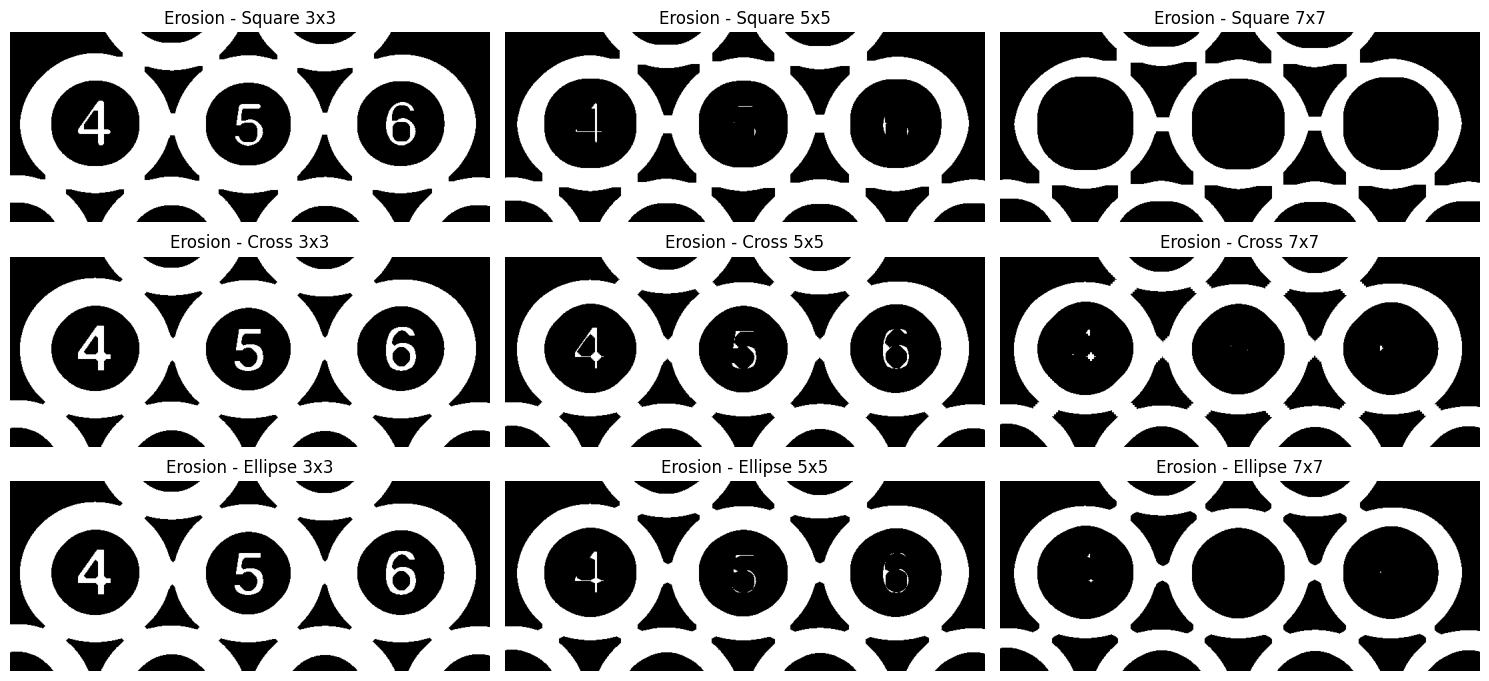

In [4]:
# Zoom on balls 4, 5 and 6 so the small differences are easy to see
crop = (slice(455, 740), slice(280, 1000))

def show_grid(op, op_name, out_file):
    plt.figure(figsize=(15, 7))
    i = 1
    for name, shape in shapes.items():
        for s in sizes:
            k = cv2.getStructuringElement(shape, (s, s))
            result = op(binary, k, iterations=3)
            white = np.count_nonzero(result)
            print(f'{op_name:8s} {name:8s} {s}x{s}: white pixels = {white}')
            plt.subplot(3, 3, i)
            plt.imshow(result[crop], 'gray')
            plt.title(f'{op_name} - {name} {s}x{s}')
            plt.axis('off')
            i += 1
    plt.tight_layout()
    plt.savefig(out_file, dpi=110, bbox_inches='tight')
    plt.show()

print('Original white pixels =', np.count_nonzero(binary))
show_grid(cv2.erode, 'Erosion', 'results/task2_erosion.png')

Dilation Square   3x3: white pixels = 599496
Dilation Square   5x5: white pixels = 691970
Dilation Square   7x7: white pixels = 775537
Dilation Cross    3x3: white pixels = 580931
Dilation Cross    5x5: white pixels = 657895
Dilation Cross    7x7: white pixels = 730426
Dilation Ellipse  3x3: white pixels = 580931
Dilation Ellipse  5x5: white pixels = 671099
Dilation Ellipse  7x7: white pixels = 743236


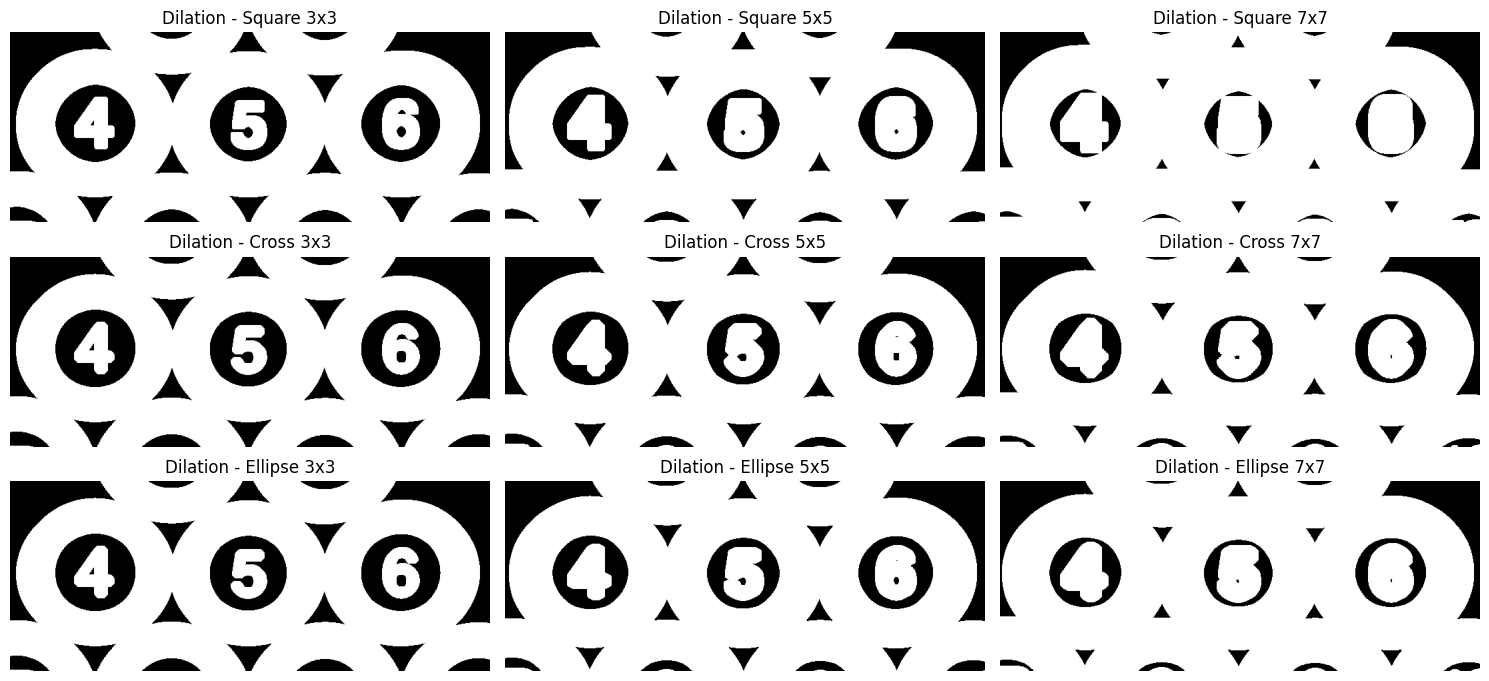

In [5]:
show_grid(cv2.dilate, 'Dilation', 'results/task2_dilation.png')

### Comparison (Task 2)

Each operation was applied with 3 iterations so the differences between the shapes are easier to see.

- **Kernel size:** a bigger kernel gives a stronger effect. With 3x3 the change is small, and with 7x7 erosion makes the rings and digits much thinner, while dilation makes them much thicker and fills the gaps between the balls.
- **Square:** the strongest effect, because it covers all pixels in the window. It also makes round edges look a bit boxy.
- **Cross:** the weakest effect, because it only uses the middle row and column. Diagonal edges change less than horizontal and vertical ones.
- **Ellipse:** between square and cross, and it keeps the round shape of the balls best, so it is the most suitable shape for this image. (In OpenCV the 3x3 ellipse is the same as the 3x3 cross, so their results are identical.)